# Chlorella cultivation model reanalysis

The analysis uses 630 observations from 90 independent culture flasks, grouped into 80 distinct cultivation settings. It reproduces the validation and held-out test metrics used in the revision, Figure 4–6 data, and the flask- and condition-level results.

| Evaluation | Unit held out | Purpose |
|---|---|---|
| Record-level random split | 126 records | Compare four candidate models on the held-out subset after selection by validation R² |
| Leave one flask out | One culture flask per fold, 90 folds | Assess prediction for a held-out flask |
| Leave one condition out | All flasks sharing one setting per fold, 80 folds | Assess prediction for cultivation settings unseen in training |

The supplied reference outputs let readers open and run this notebook without fitting all models first. To refit models, select fresh mode in the setup cell or use the commands in the README.

## 1. Setup

In [1]:
import os
import subprocess
import sys
from pathlib import Path

os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
from IPython.display import display

from repro.data import DATA, DAY_COLUMN, ROOT, load_data
from repro.report import export_tables, key_results, load_results
from repro.charts import render

mode = os.environ.get("CHLORELLA_RUN_MODE", "reference")
if mode not in {"reference", "fresh"}:
    raise ValueError("Choose reference or fresh mode.")
workers = int(os.environ.get("CHLORELLA_WORKERS", "6"))
runs = Path(os.environ.get("CHLORELLA_OUTPUT_DIR", ROOT / "outputs")).resolve()
reports = runs / f"{mode}_report"
print(f"Mode: {mode}")

Mode: reference


## 2. Load the data

The first 17 columns contain the predictors and the next two contain the measured outcomes. A row records one daily measurement. The flask identifier links the seven days for one culture, and the condition identifier links separately cultivated flasks with matching settings. The replicate identifier denotes a flask within its condition. Grouping and historical metadata are excluded from the predictors.

In [2]:
data = load_data(DATA)
overview = {
    "Daily observations": len(data),
    "Independent flasks": data.bottle_id.nunique(),
    "Condition groups": data.condition_id.nunique(),
    "Corrected cultivation-day labels": int(data[DAY_COLUMN].ne(data.original_day_label).sum()),
}
display(overview)
display(data[["source_row", "condition_id", "bottle_id", "replicate_id", DAY_COLUMN]].head())

{'Daily observations': 630,
 'Independent flasks': 90,
 'Condition groups': 80,
 'Corrected cultivation-day labels': 15}

,source_row,condition_id,bottle_id,replicate_id,time(d)
0,1,1,1,1,1
1,2,2,2,1,1
2,3,3,3,1,1
3,4,4,4,1,1
4,5,5,5,1,1


## 3. Record-level comparison

The seeded split uses 403 training records, 101 validation records, and 126 held-out test records. RFECV is fitted within the training portion of each tuning fold. The composite target uses the minimum and maximum values from the corresponding training data. The highest validation R² determines the selected model for each target.

In [3]:
def fit(module, name, *args):
    command = [sys.executable, "-m", module, "--data", str(DATA),
               "--output", str(runs / name), "--workers", str(workers), *args]
    subprocess.run(command, cwd=ROOT, check=True)

if mode == "fresh":
    fit("repro.record_level", "record")

## 4. Grouped cross-validation

Both grouped evaluations use CatBoost with five-fold grouped tuning inside every outer training partition. In each condition holdout, no record from a flask sharing the held-out cultivation setting participates in training or tuning. In the flask holdout, other flasks with the same setting may occur in the outer training partition.

In [4]:
if mode == "fresh":
    for protocol in ("condition", "bottle"):
        fit("repro.grouped", protocol, "--protocol", protocol)

## 5. Model scores and settings

The following checks compare the metrics against the archived results. They also verify the record assignments and the number of held-out predictions.

In [5]:
metrics, predictions, settings, grouped = load_results(mode, runs)
winners, grouped_metrics = key_results(data, metrics, predictions, grouped)
export_tables(metrics, settings, grouped_metrics, reports)
display(winners[["target", "model", "validation_r2", "test_r2", "test_rmse", "test_mae"]].round(5))
display(grouped_metrics.round(4))

,target,model,validation_r2,test_r2,test_rmse,test_mae
2,Biomass,CatBoost,0.96544,0.95794,34.79622,24.18771
10,Normalized composite objective,CatBoost,0.96562,0.95548,0.10928,0.08108
6,Total chlorophyll,CatBoost,0.94089,0.93014,3.60547,2.70308


,protocol,target,folds,r2,rmse,mae
0,condition,Biomass,80,0.6136,101.7245,60.6385
1,condition,Normalized composite objective,80,0.6117,0.3111,0.1969
2,condition,Total chlorophyll,80,0.5799,8.5116,5.6433
3,bottle,Biomass,90,0.6751,93.2793,56.6036
4,bottle,Normalized composite objective,90,0.6582,0.2916,0.1846
5,bottle,Total chlorophyll,90,0.6036,8.2682,5.4265


## 6. Figures and source values

The comparison figure shows validation R² and the three test metrics. The observed-versus-predicted figure shows the 403 training and 126 test records. The residual figure shows the 504 development and 126 test records. The notebook exports plotting data and editable vector PDFs.

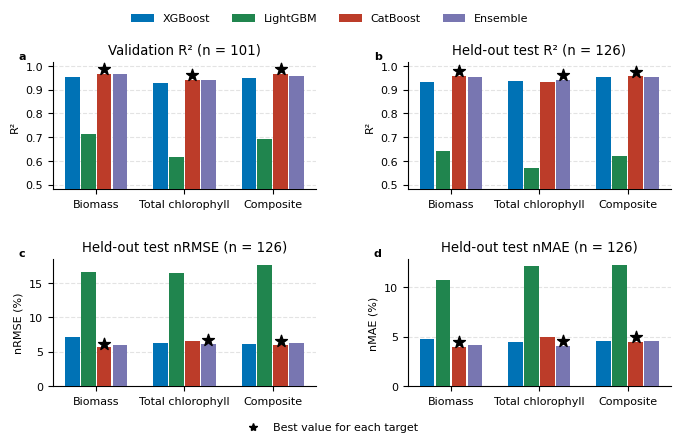

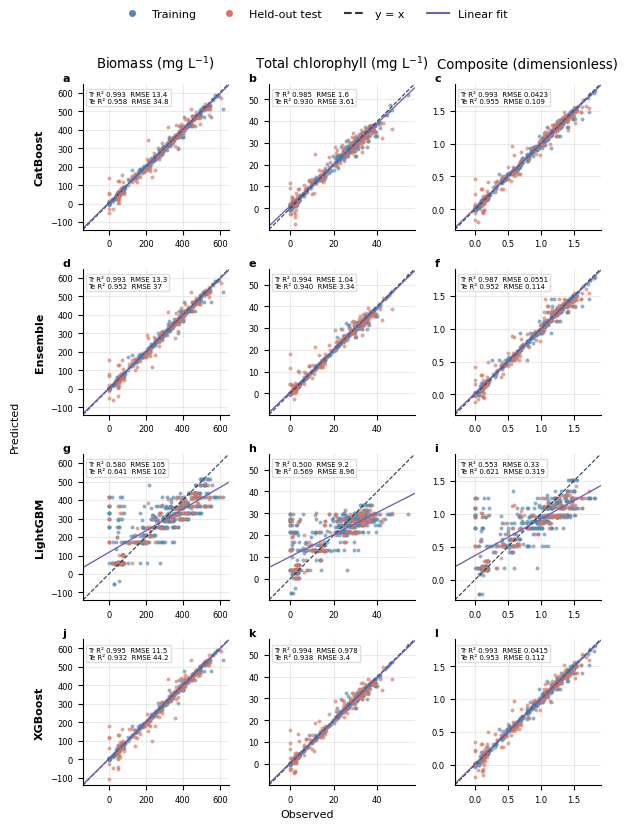

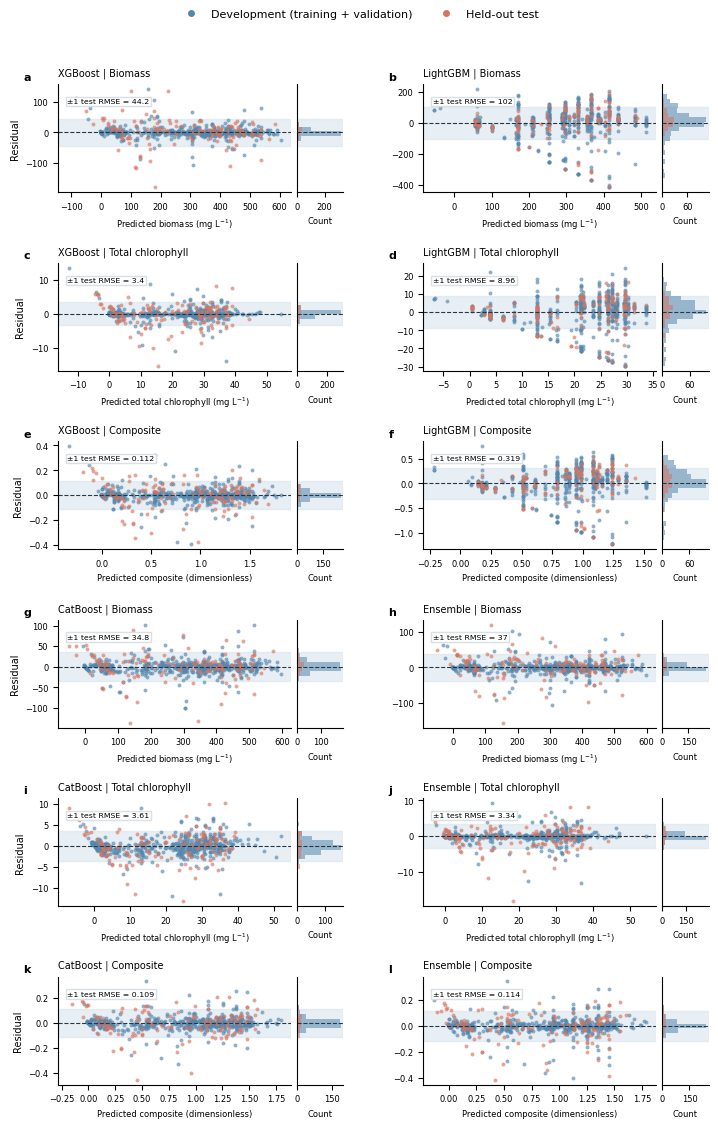

The reports and figures are saved in reference_report


In [6]:
figures = render(predictions, metrics, reports)
plt.show()
print("The reports and figures are saved in", reports.relative_to(runs))

## 7. Original SHAP, PDP, and Pareto analysis

Open [chlorella_original_analysis.ipynb](chlorella_original_analysis.ipynb) in this directory for the original workflow. Its input uses the archived day labels to maintain the provenance of the interpretation figures, optimized candidate settings, and separate laboratory validation.